<a href="https://colab.research.google.com/github/jungmee0807-droid/26-2-DIP-JeongmiMa-202301846-/blob/main/HW/HW02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Image Restoration

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E'

print(os.path.exists(os.path.join(imgpath, 'dentalXray-pepper-noise.tif')))

Mounted at /content/drive
True


In [3]:
f = plt.imread(imgpath+'/test-pattern.tif')
f.shape

(604, 604)

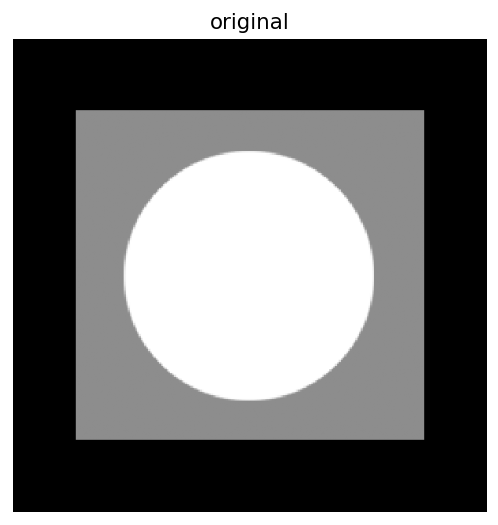

In [4]:
plt.figure(dpi=128)
plt.imshow(f, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('original')
plt.show()

### Gaussian Noise

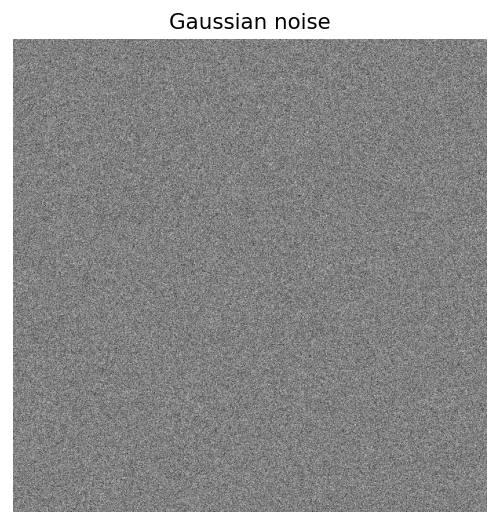

In [5]:
n_gauss = np.random.normal(0,32,f.shape)
plt.figure(dpi=128)
plt.imshow(n_gauss, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('Gaussian noise')
plt.show()

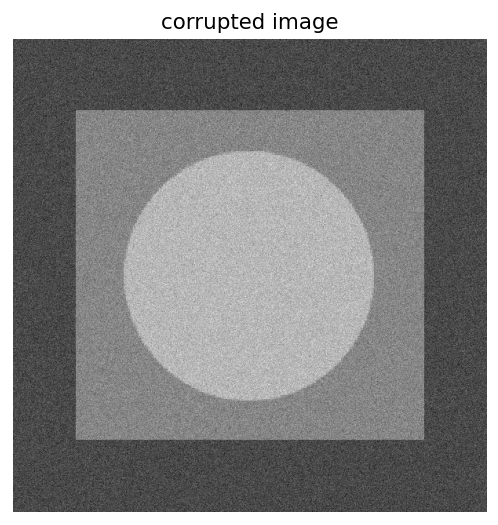

In [6]:
f_n = f + n_gauss
plt.figure(dpi=128)
plt.imshow(f_n,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.show()

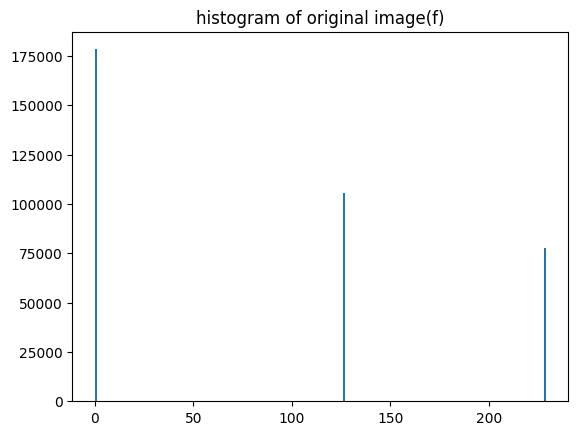

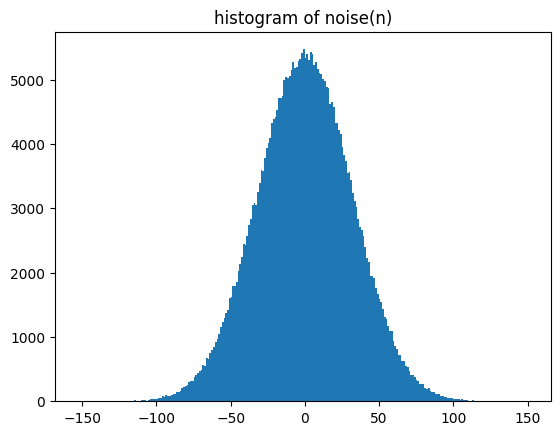

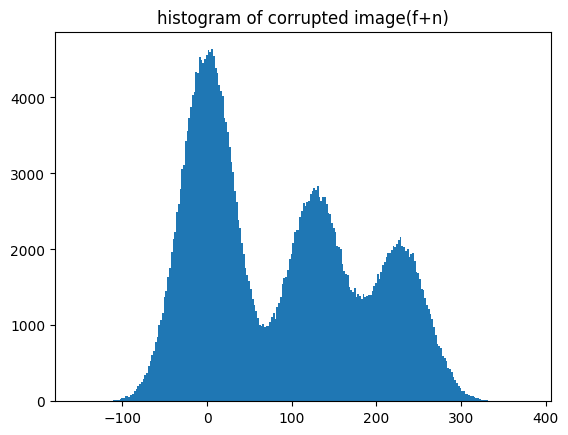

In [7]:
plt.hist(f.ravel(),256)
plt.title('histogram of original image(f)')
plt.show()
plt.hist(n_gauss.ravel(),256)
plt.title('histogram of noise(n)')
plt.show()
plt.hist(f_n.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

### Salt and Pepper Noise

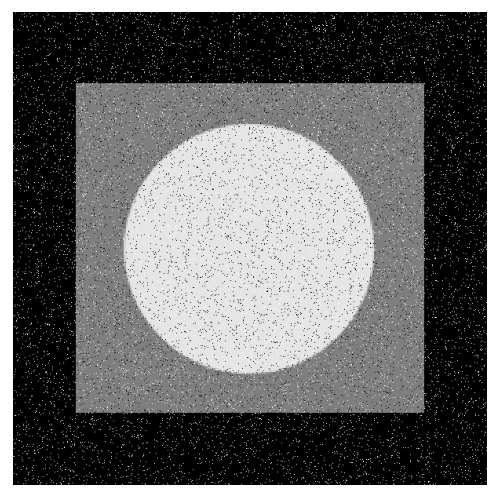

In [8]:
sp = np.random.randint(0,100,np.shape(f))
f_sp = f.copy()
f_sp[sp<3] = 0
f_sp[sp>96] = 255

plt.figure(dpi=128)
plt.imshow(f_sp,cmap='gray',aspect='equal')
plt.axis('off')
plt.show()

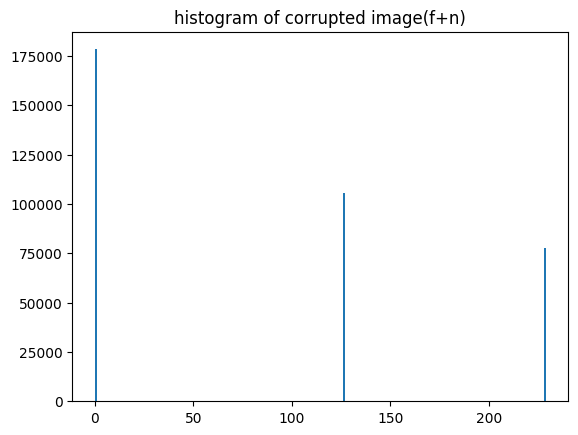

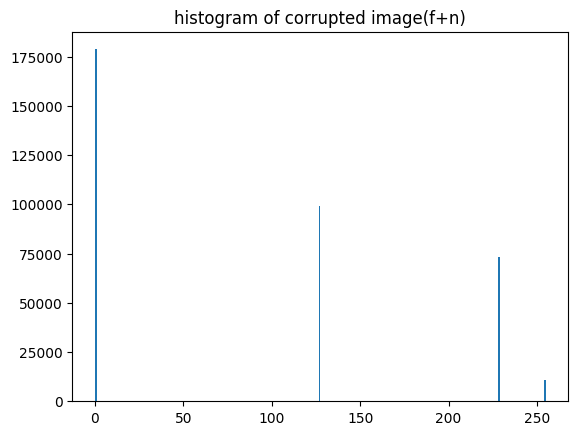

In [9]:
plt.hist(f.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

plt.hist(f_sp.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

### Mean vs Median Filtering

In [10]:
SS = 7 # kernel size (square kernel)
ss = int((SS-1)/2)
r_median = np.zeros(np.shape(f_sp))
r_mean = np.zeros(np.shape(f_sp))

In [12]:
for x in range(ss,np.size(f_sp,0)-ss):
  for y in range(ss,np.size(f_sp,1)-ss):
    Sxy = f_sp[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    r_median[x,y] = np.median(Sxy)

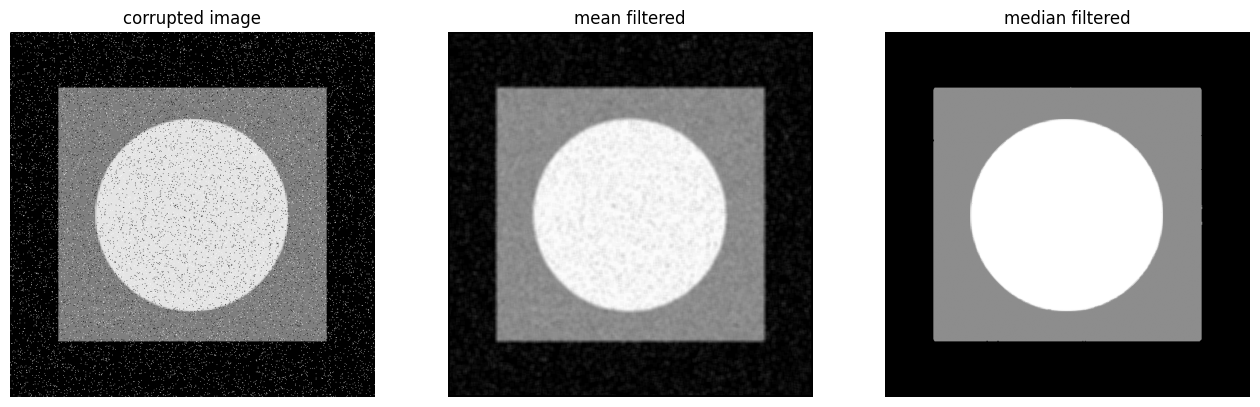

In [13]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f_sp,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_median,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('median filtered')
plt.show()

## Adaptive Local Noise Reduction

In [14]:
# Adaptive local noise reduction
f = f_n

std_eta = 16
SS = 5

ss = int((SS-1)/2)
r_amean = np.zeros(np.shape(f))
for x in range(ss,np.size(f,0)-ss):
  for y in range(ss,np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    std_Sxy = np.std(Sxy)
    r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))

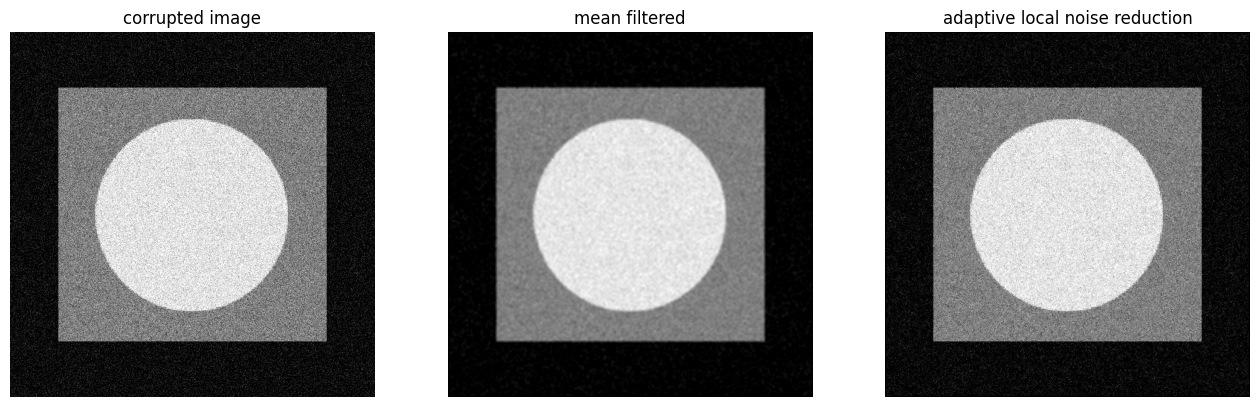

In [15]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f_n,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_amean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction')
plt.show()

## Adaptive Median Filtering

In [16]:
# Adaptive Median Filtering
#f = f_sp
f = plt.imread(imgpath+'/circuitboard-saltandpep.tif')
SS_vals = np.array([3, 5, 7])
r_amedian = np.zeros(np.shape(f))
r_median = np.zeros(np.shape(f))
r_case = np.zeros(np.shape(f))

ss_max = int((np.max(SS_vals)-1)/2)
for x in range(ss_max,np.size(f,0)-ss_max):
  for y in range(ss_max,np.size(f,1)-ss_max):
    flag_go = 1
    cnt = 0
    z_xy = f[x,y]
    for SS in SS_vals:
      ss = int((SS-1)/2)
      Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
      z_med = np.median(Sxy)
      z_min = np.min(Sxy)
      z_max = np.max(Sxy)

      if cnt==0:
        r_median[x,y] = z_med

      if z_min<z_med and z_med<z_max:
        if z_min<z_xy and z_xy<z_max:
          r_amedian[x,y] = z_xy
          flag_go = 0
        else:
          r_amedian[x,y] = z_med
          flag_go = 0
      else:
        if SS == np.max(SS_vals):
          r_amedian[x,y] = z_med
          flag_go = 0

      if flag_go==0:
        r_case[x,y] = cnt
        break
      cnt = cnt+1

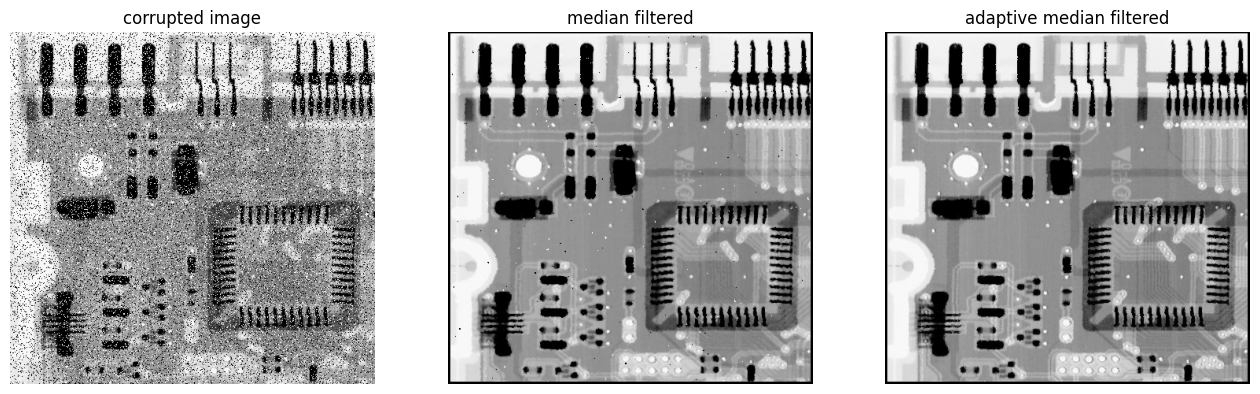

In [17]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_median,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('median filtered')
plt.subplot(133)
plt.imshow(r_amedian,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive median filtered')
plt.show()

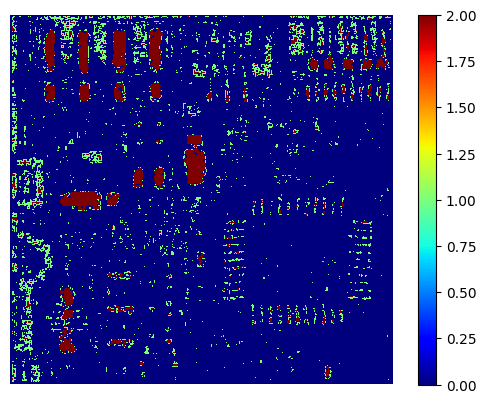

In [18]:
plt.imshow(r_case,cmap='jet',interpolation='nearest')
plt.axis('off')
plt.colorbar()
plt.show()

## Exercise
- 두 개의 noisy image를 각각 f1, f2로 불러오고 적절한 restoration(denoising)을 수행해보자.

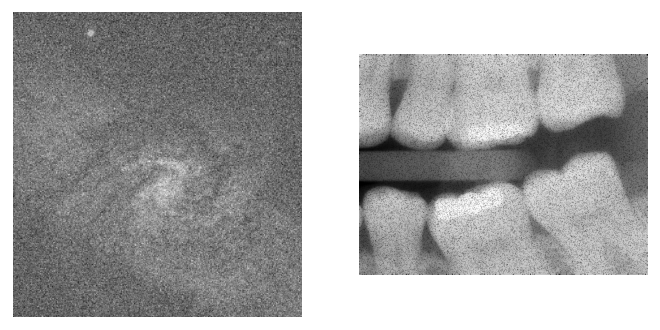

In [19]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

- 복원코드를 직접 작성해보기.

(680, 888) 0.0 255.0


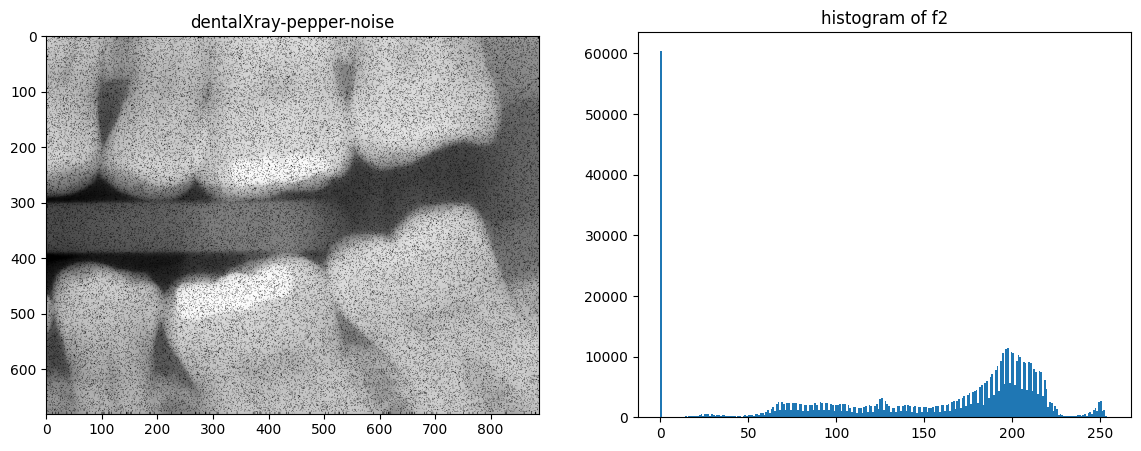

In [20]:
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')
if f2.ndim == 3:            # 컬러(3채널)로 읽히면 한 채널만 사용
    f2 = f2[..., 0]
f2 = f2.astype(float)       # 계산을 위해 실수형으로
print(f2.shape, f2.min(), f2.max())

plt.figure(figsize=(14,5))
plt.subplot(121)
plt.imshow(f2, cmap='gray', vmin=0, vmax=255)
plt.title('dentalXray-pepper-noise')
plt.subplot(122)
plt.hist(f2.ravel(), 256)
plt.title('histogram of f2')
plt.show()

불러오기 및 노이즈 확인

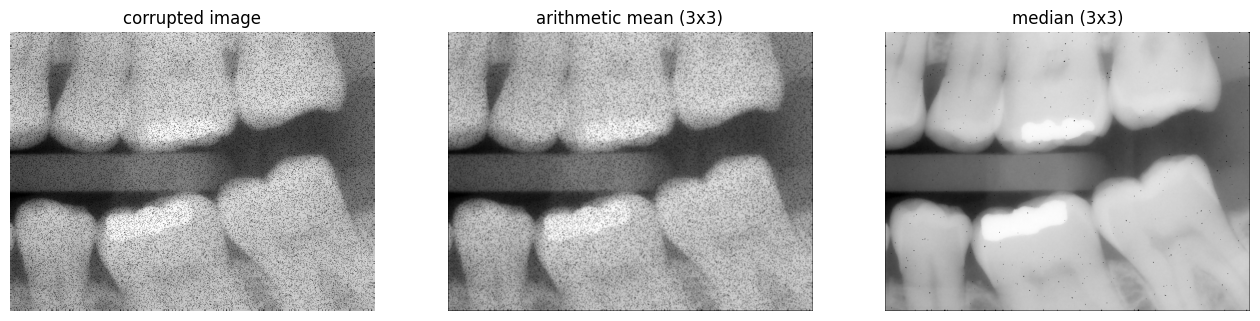

In [21]:
SS = 3 # kernel size (square kernel)
ss = int((SS-1)/2)
r_median = np.zeros(np.shape(f2))
r_mean = np.zeros(np.shape(f2))

for x in range(ss,np.size(f2,0)-ss):
  for y in range(ss,np.size(f2,1)-ss):
    Sxy = f2[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    r_median[x,y] = np.median(Sxy)

plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f2,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.title(f'arithmetic mean ({SS}x{SS})')
plt.subplot(133)
plt.imshow(r_median,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.title(f'median ({SS}x{SS})')
plt.show()

1번 Arithmetic Mean, 2번 Median

noise std (std_eta) = 35.6


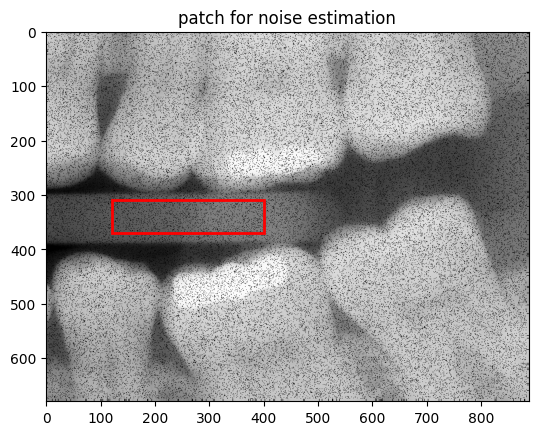

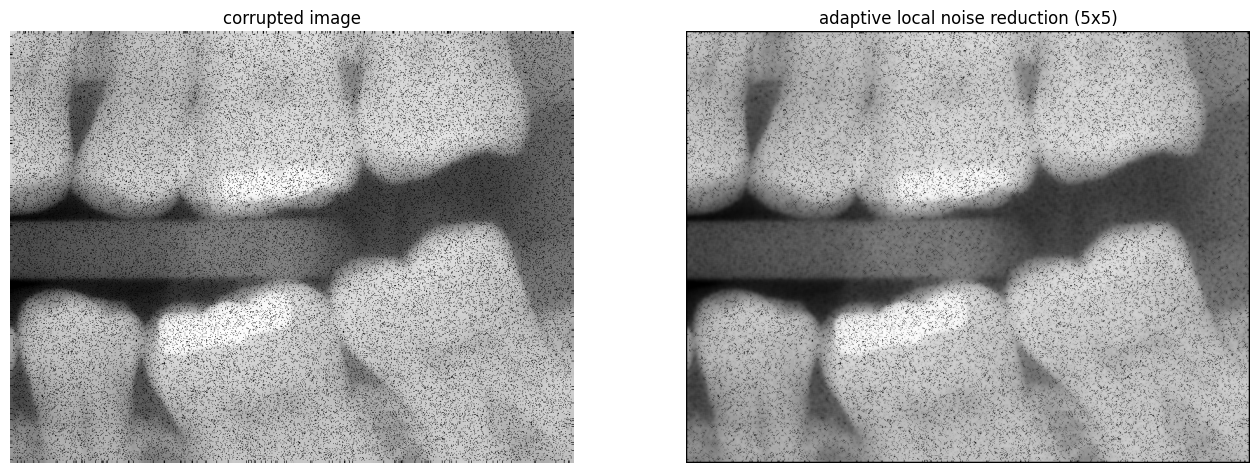

In [22]:
# (1) 평평한 영역에서 노이즈 크기 추정
patch = f2[310:370, 120:400]          # 치아 사이 회색 띠
std_eta = np.std(patch)
print('noise std (std_eta) =', round(std_eta, 1))

plt.imshow(f2, cmap='gray', vmin=0, vmax=255)
plt.gca().add_patch(plt.Rectangle((120, 310), 280, 60, fill=False, ec='r', lw=2))
plt.title('patch for noise estimation')
plt.show()

# (2) Adaptive local noise reduction
SS = 5
ss = int((SS-1)/2)
r_amean = np.zeros(np.shape(f2))
for x in range(ss,np.size(f2,0)-ss):
  for y in range(ss,np.size(f2,1)-ss):
    Sxy = f2[x-ss:x-ss+SS,y-ss:y-ss+SS]
    var_Sxy = np.var(Sxy)
    if var_Sxy > 0:
      ratio = (std_eta*std_eta)/var_Sxy
    else:
      ratio = 1
    ratio = min(ratio, 1)               # 교재: 비율이 1보다 크면 1로 고정
    r_amean[x,y] = f2[x,y] - ratio*(f2[x,y]-np.mean(Sxy))

plt.figure(figsize=(16,9))
plt.subplot(121)
plt.imshow(f2,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(122)
plt.imshow(r_amean,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.title(f'adaptive local noise reduction ({SS}x{SS})')
plt.show()

(598, 566) 0.0 255.0


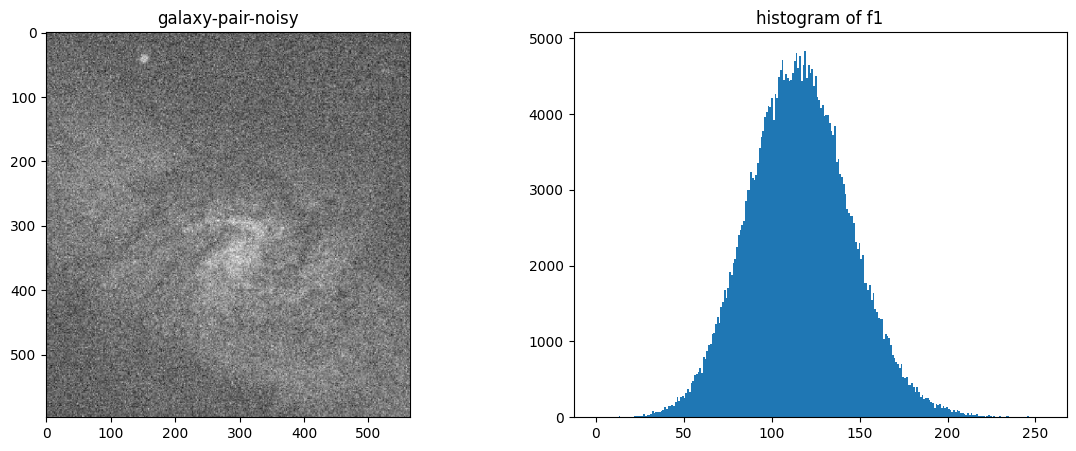

In [23]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
if f1.ndim == 3:
    f1 = f1[..., 0]
f1 = f1.astype(float)
print(f1.shape, f1.min(), f1.max())

plt.figure(figsize=(14,5))
plt.subplot(121)
plt.imshow(f1, cmap='gray', vmin=0, vmax=255)
plt.title('galaxy-pair-noisy')
plt.subplot(122)
plt.hist(f1.ravel(), 256)
plt.title('histogram of f1')
plt.show()

In [24]:
def mean_median_filter(f, SS):
    ss = int((SS-1)/2)
    r_mean = np.zeros(np.shape(f))
    r_median = np.zeros(np.shape(f))
    for x in range(ss,np.size(f,0)-ss):
      for y in range(ss,np.size(f,1)-ss):
        Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
        r_mean[x,y] = np.mean(Sxy)
        r_median[x,y] = np.median(Sxy)
    return r_mean, r_median

def adaptive_local(f, std_eta, SS):
    ss = int((SS-1)/2)
    r_amean = np.zeros(np.shape(f))
    for x in range(ss,np.size(f,0)-ss):
      for y in range(ss,np.size(f,1)-ss):
        Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
        var_Sxy = np.var(Sxy)
        ratio = (std_eta*std_eta)/var_Sxy if var_Sxy > 0 else 1
        ratio = min(ratio, 1)
        r_amean[x,y] = f[x,y] - ratio*(f[x,y]-np.mean(Sxy))
    return r_amean

noise std (std_eta) = 25.2


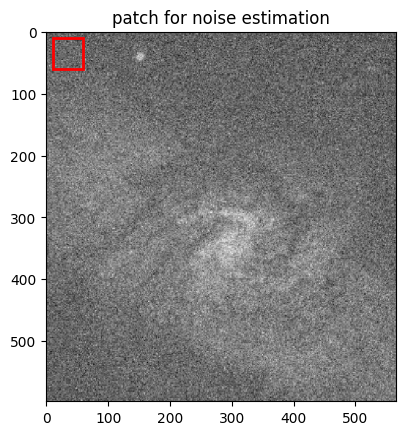

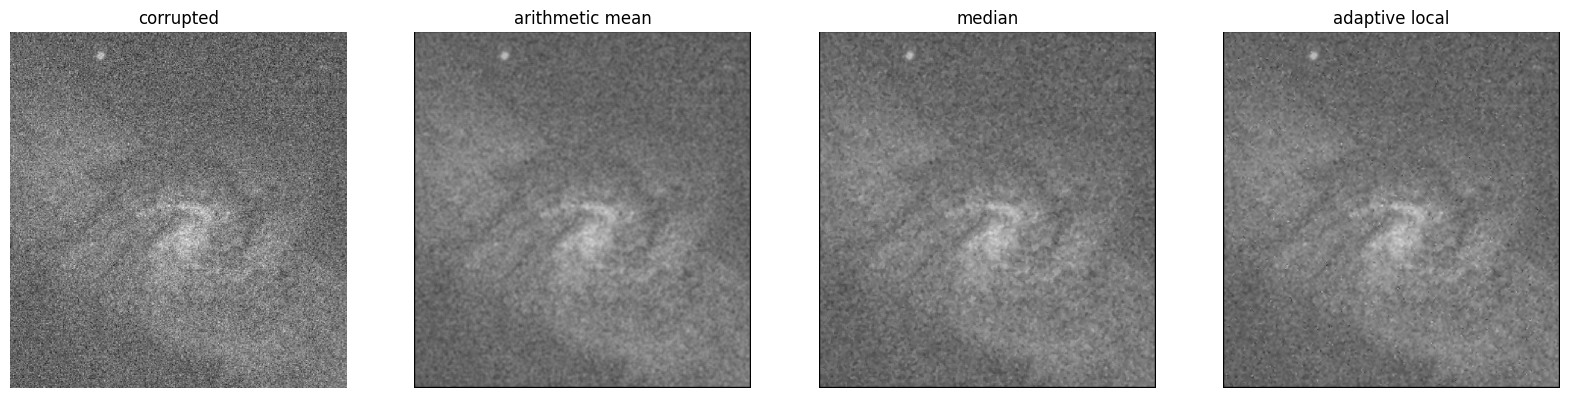

In [25]:
# 노이즈 크기 추정 (은하/별이 없는 배경으로 좌표 조정!)
patch_g = f1[10:60, 10:60]
std_eta_g = np.std(patch_g)
print('noise std (std_eta) =', round(std_eta_g, 1))

plt.imshow(f1, cmap='gray', vmin=0, vmax=255)
plt.gca().add_patch(plt.Rectangle((10, 10), 50, 50, fill=False, ec='r', lw=2))
plt.title('patch for noise estimation')
plt.show()

g_mean, g_median = mean_median_filter(f1, 5)
g_amean = adaptive_local(f1, std_eta_g, 5)

results = [f1, g_mean, g_median, g_amean]
titles  = ['corrupted', 'arithmetic mean', 'median', 'adaptive local']
plt.figure(figsize=(20,5))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.imshow(results[i], cmap='gray', vmin=0, vmax=255)
    plt.axis('off'); plt.title(titles[i])
plt.show()

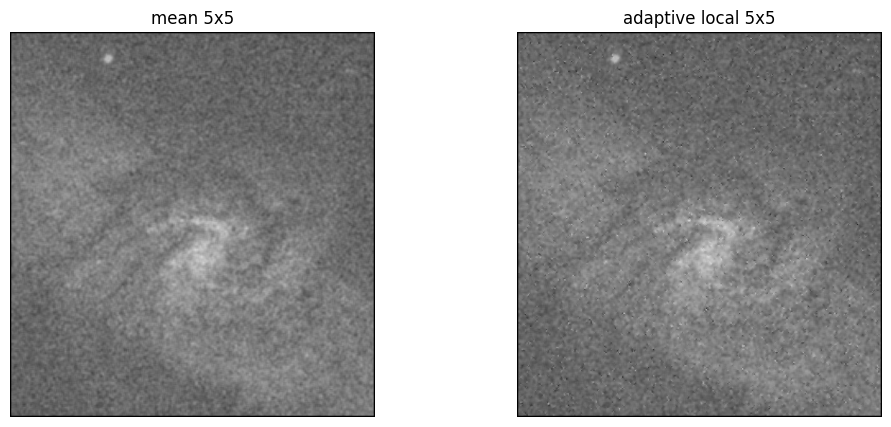

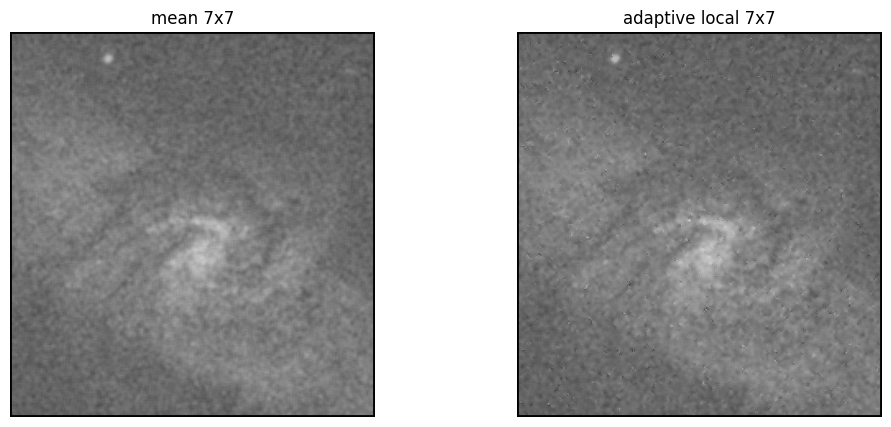

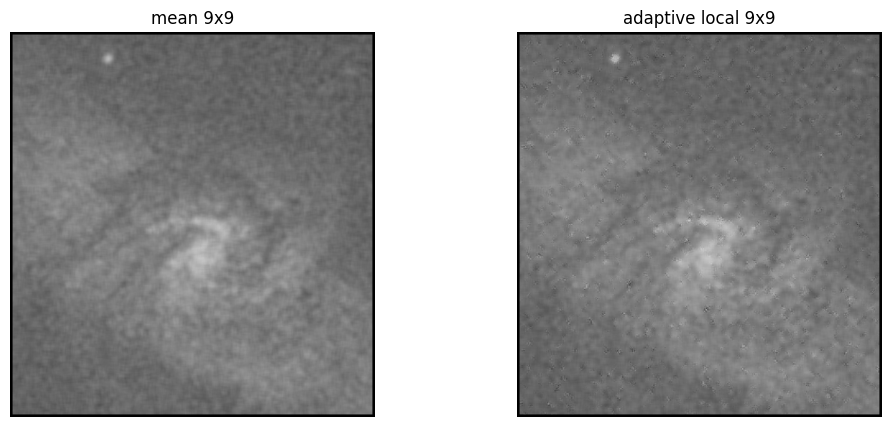

In [28]:
for SS in [5, 7, 9]:
    g_amean_SS = adaptive_local(f1, std_eta_g, SS)
    g_mean_SS, _ = mean_median_filter(f1, SS)
    plt.figure(figsize=(12,5))
    plt.subplot(121); plt.imshow(g_mean_SS, cmap='gray', vmin=0, vmax=255); plt.axis('off'); plt.title(f'mean {SS}x{SS}')
    plt.subplot(122); plt.imshow(g_amean_SS, cmap='gray', vmin=0, vmax=255); plt.axis('off'); plt.title(f'adaptive local {SS}x{SS}')
    plt.show()
    if SS == 7:
        g_amean7 = g_amean_SS     # 7x7 결과 따로 저장

- 복원된 f1, f2를 시각화하기

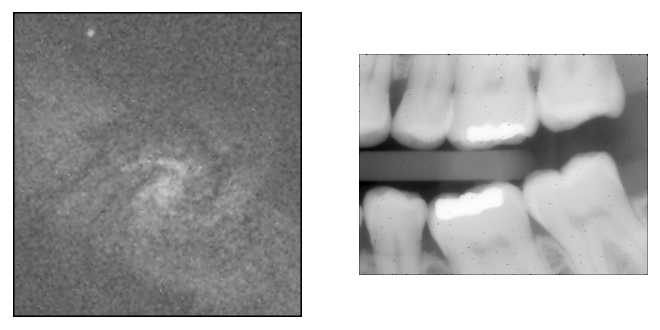

In [29]:
f1_r = g_amean7     # galaxy: adaptive local 7x7
f2_r = r_median     # dental: median 3x3
plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1_r,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.subplot(122)
plt.imshow(f2_r,cmap='gray',vmin=0,vmax=255)
plt.axis('off')
plt.show()

plt.imsave('denoised-galaxy-pair.png',f1_r,cmap='gray',vmin=0,vmax=255)
plt.imsave('denoised-dentalXray.png',f2_r,cmap='gray',vmin=0,vmax=255)

- 복원된 f1, f2를 그림파일로 저장하기

In [30]:
  plt.imsave('denoised-galaxy-pair.png',f1_r,cmap='gray',vmin=0,vmax=255)
  plt.imsave('denoised-dentalXray.png',f2_r,cmap='gray',vmin=0,vmax=255)